# Data-Driven Traffic Safety: Identifying High-Risk Crash Locations and Conditions in Colorado

## Project Overview

Traffic crashes are an important transportation safety issue in Colorado. Understanding where crashes occur and the conditions surrounding them can help transportation and traffic-safety agencies identify areas that may need further investigation.

For this project, I am using **Colorado Department of Transportation (CDOT) crash data from 2025**. The dataset contains information about reported crashes across Colorado, including crash location, date and time, weather, road conditions, lighting conditions, vehicles, injuries, and fatalities.

The main goal of this project is to explore the data and identify **locations and conditions associated with higher concentrations of reported crashes and crashes involving injuries or fatalities**.

The findings will not be used to determine the exact cause of a crash or to give real-time driving recommendations. Instead, the results can help transportation agencies identify patterns and locations that may deserve further safety investigation and potential improvements.

## Research Question

**Can crash, road, weather, time, and location data be used to identify high-risk conditions and locations that transportation agencies can prioritize for further safety investigation and potential improvements?**

To answer this question, I will explore patterns in:

- Crash locations
- Time and day of crashes
- Weather conditions
- Road conditions
- Lighting conditions
- Crash characteristics
- Crashes involving injuries or fatalities

## Stakeholder and Potential Action

### Stakeholder

The primary stakeholders are **Colorado transportation and traffic-safety agencies**.

### Potential Action

The analysis can help agencies identify **high-crash-concentration locations and conditions** that should be considered for further investigation.

Depending on the findings and additional information available to the agency, these areas could be considered for actions such as reviewing roadway conditions, warning signs, lighting, intersections, or other safety improvements.

The analysis provides evidence for prioritization, but it does not determine which specific intervention should be implemented.

## Dataset

This project uses the **Colorado Department of Transportation (CDOT) 2025 Crash Listing dataset**.

The dataset contains:

- **95,696 reported crash records**
- **110 variables**
- Crash date and time
- City and county
- Latitude and longitude
- Road information
- Weather conditions
- Road conditions
- Lighting conditions
- Construction and school zone information
- Vehicle information
- Driver-related information
- Number of injuries
- Number of fatalities

Because this project uses only **2025 data**, the analysis represents crash patterns within that year rather than long-term trends across multiple years.

## Analysis Plan

I will begin with exploratory data analysis (EDA) to understand the structure and quality of the crash data.

The analysis will include:

1. Checking the size and structure of the dataset.
2. Examining missing values in important variables.
3. Cleaning and preparing date and time variables.
4. Examining crash patterns by county and city.
5. Examining crash patterns by day and hour.
6. Exploring weather, road, and lighting conditions.
7. Examining the geographic distribution of crashes using latitude and longitude.
8. Identifying locations with high concentrations of reported crashes.
9. Comparing conditions with crashes involving injuries or fatalities.
10. Selecting the most useful variables for the next stage of the project.

The goal of the EDA is to identify one strong finding that can be connected to a practical transportation-safety implication.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv("CDOTRM_CD_Crash_Listing_-_2025.csv", low_memory=False)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Rows: 95696
Columns: 110


,CUID,System Code,Rd_Number,Rd_Section,City_Street,Crash Date,Crash Time,Agency Id,City,County,...,TU-2 NM Safety Helmet,TU-1 NM Alcohol Suspected,TU-2 NM Alcohol Suspected,TU-1 NM Marijuana Suspected,TU-2 NM Marijuana Suspected,TU-1 NM Other Drugs Suspected,TU-2 NM Other Drugs Suspected,Record Status,Processing Status,Last Updated
0,1259573,City Street,1285,107TH,CHERR,1/1/25,00:00:00,THPD,THORNTON,ADAMS,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coded,Completed,Nov 26 2025 6:58PM
1,1267933,City Street,0760,AMMON,001HS,1/1/25,00:00:00,LPD,LAKEWOOD,JEFFERSON,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coded,Completed,Feb 6 2025 3:06PM
2,1274358,City Street,0320,DAKOT,PEARL,1/1/25,00:01:00,DPD,DENVER,DENVER,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coded,Completed,May 5 2025 3:03PM
3,1535586,County Road,2100,CHIPE,ORCHI,1/1/25,00:01:00,CSP,NaN,MONTROSE,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coded,Completed,Jun 12 2025 2:52PM
4,1259491,City Street,0320,A0018,GRANT,1/1/25,00:05:00,DPD,DENVER,DENVER,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Coded,Completed,Jan 8 2025 3:18PM


# Reviewing the Available Variables

The dataset contains information about crash location, date and time, roadway characteristics, weather, lighting, vehicles, drivers, injuries, and fatalities.

Because there are 110 variables, I will focus the analysis on variables that are directly related to my research question.

In [3]:
print(df.columns.tolist())

['CUID', 'System Code', 'Rd_Number', 'Rd_Section', 'City_Street', 'Crash Date', 'Crash Time', 'Agency Id', 'City', 'County', 'Latitude', 'Longitude', 'Location 1', 'Link', 'Location 2', 'Location', 'Road Description', 'First HE', 'Second HE', 'Third HE', 'Fourth HE', 'MHE', 'Crash Type', 'Approach Overtaking Turn', 'Wild Animal', 'Number Killed', 'Number Injured', 'Injury 00', 'Injury 01', 'Injury 02', 'Injury 03', 'Injury 04', 'Total Vehicles', 'Secondary Crash', 'Construction Zone', 'School Zone', 'Road Contour Curves', 'Road Contour Grade', 'Road Condition', 'Lighting Conditions', 'Weather Condition', 'Weather Condition 2', 'Lane Position', 'TU-1 Direction', 'TU-2 Direction', 'TU-1 Movement', 'TU-2 Movement', 'TU-1 Type', 'TU-2 Type', 'TU-1 Special Function', 'TU-2 Special Function', 'TU-1 Autonomous Vehicle', 'TU-2 Autonomous Vehicle', 'TU-1 Hit And Run', 'TU-2 Hit And Run', 'TU-1 Speed Limit', 'TU-2 Speed Limit', 'TU-1 Estimated Speed', 'TU-2 Estimated Speed', 'TU-1 Speed', 'TU-2 

## Selecting Variables for the Analysis

I selected variables related to crash timing, location, roadway conditions, environmental conditions, and crash outcomes.

These variables will allow me to examine where crashes occur, when they occur, and the conditions surrounding them.

In [4]:
important_cols = [
    "Crash Date",
    "Crash Time",
    "City",
    "County",
    "Latitude",
    "Longitude",
    "Road Condition",
    "Lighting Conditions",
    "Weather Condition",
    "Weather Condition 2",
    "Construction Zone",
    "School Zone",
    "Road Contour Curves",
    "Road Contour Grade",
    "Crash Type",
    "Number Killed",
    "Number Injured",
    "Total Vehicles"
]

for col in important_cols:
    print(col, "->", col in df.columns)

Crash Date -> True
Crash Time -> True
City -> True
County -> True
Latitude -> True
Longitude -> True
Road Condition -> True
Lighting Conditions -> True
Weather Condition -> True
Weather Condition 2 -> True
Construction Zone -> True
School Zone -> True
Road Contour Curves -> True
Road Contour Grade -> True
Crash Type -> True
Number Killed -> True
Number Injured -> True
Total Vehicles -> True


## Checking Missing Data

Before continuing with the analysis, I checked the dataset for missing values.

This is important because some variables have a large amount of missing information. Variables with substantial missingness may not be appropriate for the main analysis without additional cleaning or interpretation.

In [5]:
missing = pd.DataFrame({
    "Missing": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2)
})

missing = missing.sort_values("Missing", ascending=False)

print(missing.head(30))

                                    Missing  Missing %
TU-1 NM Other Drugs Suspected         94660      98.92
TU-1 NM Alcohol Suspected             94649      98.91
TU-1 NM Safety Helmet                 94622      98.88
TU-1 NM Marijuana Suspected           94611      98.87
TU-1 NM Human Contributing Factor     94562      98.81
TU-1 NM Age                           94558      98.81
TU-1 NM Sex                           94497      98.75
TU-1 NM Action                        94497      98.75
TU-1 NM Type                          94497      98.75
TU-1 NM Movement                      94497      98.75
TU-1 NM Location                      94497      98.75
TU-1 NM Direction                     94497      98.75
TU-2 NM Other Drugs Suspected         94085      98.32
TU-2 NM Alcohol Suspected             94074      98.31
TU-2 NM Safety Helmet                 94068      98.30
TU-2 NM Marijuana Suspected           94035      98.26
TU-2 NM Human Contributing Factor     94011      98.24
Fourth HE 

In [6]:
missing_important = missing.loc[
    [c for c in important_cols if c in df.columns]
]

print(missing_important)

                     Missing  Missing %
Crash Date                 0       0.00
Crash Time               183       0.19
City                   26223      27.40
County                     0       0.00
Latitude                 236       0.25
Longitude                236       0.25
Road Condition           485       0.51
Lighting Conditions      468       0.49
Weather Condition        706       0.74
Weather Condition 2    89877      93.92
Construction Zone          5       0.01
School Zone                5       0.01
Road Contour Curves     7844       8.20
Road Contour Grade      7660       8.00
Crash Type                 0       0.00
Number Killed              0       0.00
Number Injured             0       0.00
Total Vehicles             6       0.01



I next checked missing values specifically for the variables selected for this project.

Most of the main variables have relatively little missing data. For example, crash date and county have complete records, while crash time, latitude, longitude, road condition, lighting, and weather have relatively small amounts of missing information.

City has a larger amount of missing data, with 27.40% of records missing. Weather Condition 2 is also missing for 93.92% of records, so I will be cautious about relying on that variable.

## Preparing the Crash Date

The crash date is stored as text, so I converted it into a date format.

I also created additional variables for the crash year, month, month name, and day of the week. These variables will allow me to examine when crashes occurred during 2025.

In [7]:
df["Crash Date"] = pd.to_datetime(
    df["Crash Date"],
    errors="coerce"
)

df["Crash Year"] = df["Crash Date"].dt.year
df["Crash Month"] = df["Crash Date"].dt.month
df["Crash Month Name"] = df["Crash Date"].dt.month_name()
df["Day of Week"] = df["Crash Date"].dt.day_name()

/var/folders/l5/g074wj1x23j8rtmj3b6lh2p40000gn/T/ipykernel_39062/2103625860.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Crash Date"] = pd.to_datetime(


In [8]:
print(df["Crash Time"].head(20))

0     00:00:00
1     00:00:00
2     00:01:00
3     00:01:00
4     00:05:00
5     00:10:00
6     00:14:00
7     00:14:00
8     00:16:00
9     00:20:00
10    00:24:00
11    00:30:00
12    00:30:00
13    00:30:00
14    00:30:00
15    00:31:00
16    00:36:00
17    00:39:00
18    00:41:00
19    00:52:00
Name: Crash Time, dtype: str



The crash time is recorded in a time format such as 00:00:00, 00:01:00, and 00:05:00.

I will convert this information into a usable time variable so that I can examine the distribution of crashes throughout the day.

## Preparing the Crash Hour

I extracted the hour from each recorded crash time.

This creates a new variable that represents the hour of the day, making it easier to compare crash counts across different times.

In [9]:
df["Crash Time Parsed"] = pd.to_datetime(
    df["Crash Time"].astype(str),
    errors="coerce"
)

df["Crash Hour"] = df["Crash Time Parsed"].dt.hour

/var/folders/l5/g074wj1x23j8rtmj3b6lh2p40000gn/T/ipykernel_39062/2317131554.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Crash Time Parsed"] = pd.to_datetime(


In [10]:
print(df["Crash Hour"].value_counts().sort_index())

Crash Hour
0.0     1635
1.0     1382
2.0     1304
3.0      963
4.0      911
5.0     1591
6.0     2852
7.0     5298
8.0     5359
9.0     4154
10.0    4127
11.0    4918
12.0    5506
13.0    5428
14.0    5888
15.0    7245
16.0    7678
17.0    7855
18.0    5622
19.0    4086
20.0    3654
21.0    3293
22.0    2762
23.0    2002
Name: count, dtype: int64


## 9. Crash Counts by Hour

The results show that reported crashes are not evenly distributed throughout the day.

Crash counts increase during the morning and afternoon and are highest during the late afternoon. The largest number of reported crashes occurs at **5 PM (7,855 crashes)**, followed by **4 PM (7,678 crashes)** and **3 PM (7,245 crashes)**.

The lowest count occurs at **4 AM (911 crashes)**.

## 10. Creating an Injury or Fatality Indicator

The dataset does not contain one simple crash severity variable. Instead, it provides separate fields for the number of people killed and injured.

I converted these fields to numeric values and created an indicator showing whether a crash involved at least one injury or fatality.

This will be used as an outcome indicator in the exploratory analysis rather than automatically labeling a crash as severe.

In [11]:
df["Killed"] = pd.to_numeric(
    df["Number Killed"], errors="coerce"
).fillna(0)

df["Injured"] = pd.to_numeric(
    df["Number Injured"], errors="coerce"
).fillna(0)

df["Any Injury or Fatality"] = (
    (df["Killed"] > 0) | (df["Injured"] > 0)
)

In [12]:
print(df["Killed"].describe())
print(df["Injured"].describe())

count    95696.000000
mean         0.007503
std          0.095492
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          5.000000
Name: Killed, dtype: float64
count    95696.000000
mean         0.363767
std          0.735576
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max         16.000000
Name: Injured, dtype: float64


## 11. Summary of Injuries and Fatalities

The summary shows that fatalities are relatively uncommon compared with injuries.

The average number of people killed per reported crash is approximately 0.008, while the average number injured is approximately 0.364.

The maximum recorded number of people killed in a crash is 5, while the maximum number injured is 16.

In [13]:
print(
    df["Any Injury or Fatality"].value_counts()
)

Any Injury or Fatality
False    70241
True     25455
Name: count, dtype: int64


In [14]:
county_counts = (
    df["County"]
    .dropna()
    .value_counts()
    .head(15)
)

print(county_counts)

County
DENVER        15933
ADAMS         10211
EL PASO        9940
ARAPAHOE       8991
JEFFERSON      7621
WELD           6047
LARIMER        5912
DOUGLAS        4994
BOULDER        4894
PUEBLO         2987
MESA           2228
GARFIELD       1294
BROOMFIELD     1165
LA PLATA       1098
EAGLE           916
Name: count, dtype: int64


## 13. Reported Crashes by County

I will now examine where reported crashes are concentrated across Colorado.

Denver has the highest number of reported crashes in the dataset, followed by Adams, El Paso, Arapahoe, and Jefferson counties.

These counts show where crashes were concentrated in 2025, but they should not automatically be interpreted as crash risk because traffic exposure is not included.

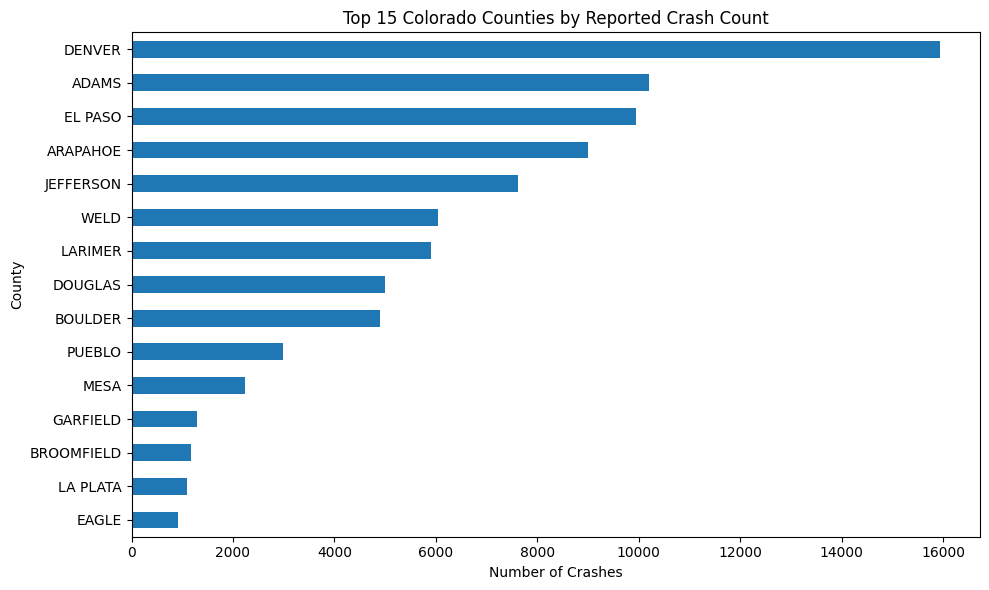

In [15]:
plt.figure(figsize=(10, 6))

county_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Colorado Counties by Reported Crash Count")
plt.xlabel("Number of Crashes")
plt.ylabel("County")
plt.tight_layout()

plt.show()

## 14. Visualizing Crash Concentration by County

The chart below shows the 15 Colorado counties with the highest numbers of reported crashes.

Denver stands out with the largest number of reported crashes, while several other counties in the Denver metropolitan area also appear near the top.

## 15. Reported Crashes by City

I next examined crash counts at the city level.

Denver has the highest number of reported crashes, followed by Colorado Springs and Aurora. This provides a more detailed view of where reported crashes were concentrated during 2025.

In [16]:
city_counts = (
    df["City"]
    .dropna()
    .value_counts()
    .head(15)
)

print(city_counts)

City
DENVER              15925
COLORADO SPRINGS     6962
AURORA               6159
FORT COLLINS         2740
LAKEWOOD             2600
PUEBLO               2093
GREELEY              1868
THORNTON             1803
LONGMONT             1723
WESTMINSTER          1673
LOVELAND             1508
GRAND JUNCTION       1342
BOULDER              1331
ARVADA               1310
COMMERCE CITY        1212
Name: count, dtype: int64


## 16. Visualizing Crash Concentration by City

The chart shows the 15 cities with the highest reported crash counts.

Denver has substantially more reported crashes than the other cities in the top 15. This makes Denver an area that could be considered for further investigation, while recognizing that population and traffic volume also affect crash counts.

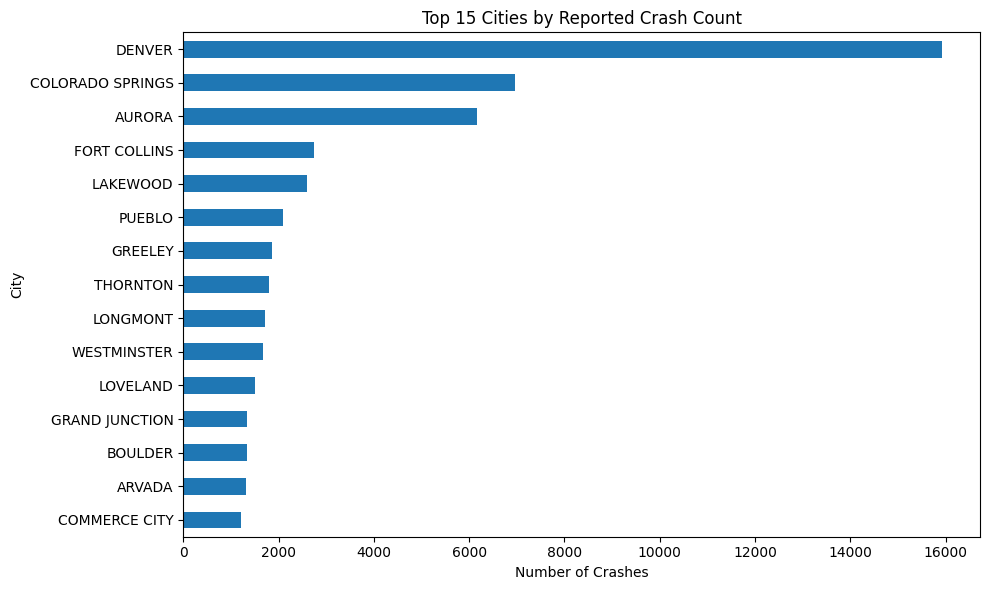

In [17]:
plt.figure(figsize=(10, 6))

city_counts.sort_values().plot(kind="barh")

plt.title("Top 15 Cities by Reported Crash Count")
plt.xlabel("Number of Crashes")
plt.ylabel("City")
plt.tight_layout()

plt.show()

In [18]:
day_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

day_counts = df["Day of Week"].value_counts().reindex(day_order)

print(day_counts)

Day of Week
Monday       13494
Tuesday      14424
Wednesday    15136
Thursday     14537
Friday       14716
Saturday     12917
Sunday       10472
Name: count, dtype: int64


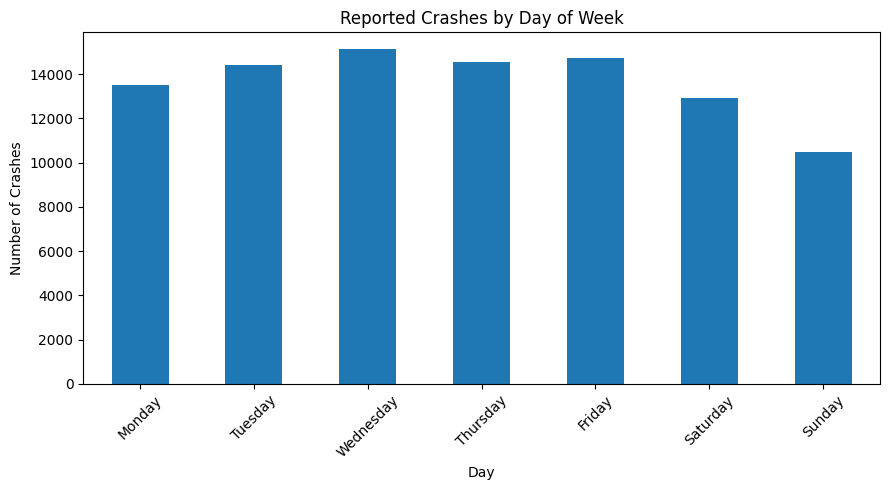

In [19]:
plt.figure(figsize=(9, 5))

day_counts.plot(kind="bar")

plt.title("Reported Crashes by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Crashes")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 17. Reported Crashes by Day of the Week

I will now examine whether crashes are distributed evenly across the days of the week.

Wednesday has the highest number of reported crashes, while Sunday has the lowest number in this dataset.

## 19. Reported Crashes by Hour of the Day

I will examine the number of reported crashes during each hour of the day.

The results provide a clearer picture of the times when crashes are most concentrated.

In [20]:
hour_counts = df["Crash Hour"].value_counts().sort_index()

print(hour_counts)

Crash Hour
0.0     1635
1.0     1382
2.0     1304
3.0      963
4.0      911
5.0     1591
6.0     2852
7.0     5298
8.0     5359
9.0     4154
10.0    4127
11.0    4918
12.0    5506
13.0    5428
14.0    5888
15.0    7245
16.0    7678
17.0    7855
18.0    5622
19.0    4086
20.0    3654
21.0    3293
22.0    2762
23.0    2002
Name: count, dtype: int64


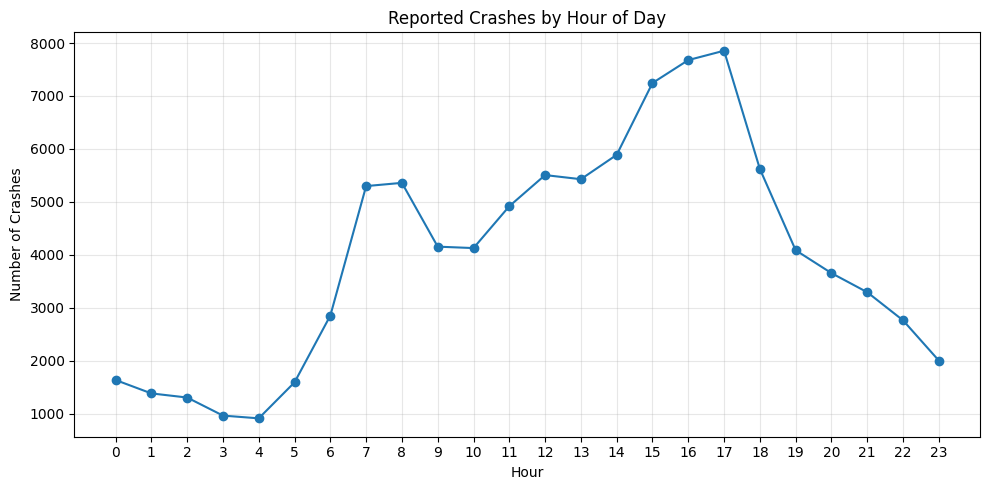

In [21]:
plt.figure(figsize=(10, 5))

hour_counts.plot(kind="line", marker="o")

plt.title("Reported Crashes by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Crashes")
plt.xticks(range(0, 24))

plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 20. Visualizing Crash Patterns Throughout the Day

The hourly pattern shows a clear increase in reported crashes during the afternoon.

Crash counts reach their highest point around **3 PM to 5 PM**, with 5 PM having the highest number of reported crashes.

This pattern is useful for identifying a time period that could be examined further in relation to traffic and roadway conditions.

## 21. Reported Crashes by Weather Condition

I will now examine the weather conditions recorded at the time of reported crashes.

Clear weather accounts for the majority of reported crashes, followed by cloudy, snow, and rain conditions.

In [22]:
print(df["Weather Condition"].value_counts(dropna=False))

Weather Condition
Clear                                78458
Cloudy                                7606
Snow                                  3807
Rain                                  3433
NaN                                    706
Wind                                   688
Blowing Snow                           403
Fog                                    277
Sleet or Hail                          148
Freezing Rain or Freezing Drizzle      143
Dust                                    27
Name: count, dtype: int64


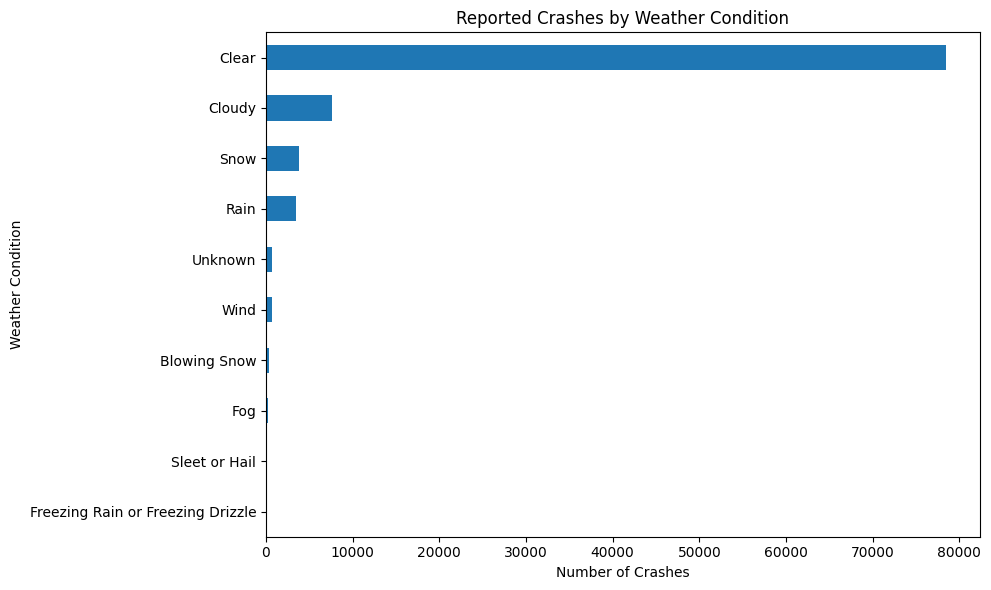

In [23]:
weather_counts = (
    df["Weather Condition"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

weather_counts.sort_values().plot(kind="barh")

plt.title("Reported Crashes by Weather Condition")
plt.xlabel("Number of Crashes")
plt.ylabel("Weather Condition")

plt.tight_layout()
plt.show()

## 22. Visualizing Crashes by Weather Condition

The results show that most reported crashes occurred under clear weather conditions, with **78,458 crashes**.

This does not mean that clear weather is more dangerous. Clear weather is also likely to be a common driving condition, so crash counts alone cannot measure the risk associated with a particular weather condition.

## 23. Reported Crashes by Road Condition

I will examine the road conditions recorded when crashes occurred.

Dry roads account for most reported crashes, followed by wet, icy, and snowy conditions.

In [24]:
print(
    df["Road Condition"]
    .value_counts(dropna=False)
)

Road Condition
Dry                                    82634
Wet                                     5565
Icy                                     3223
Snowy                                   2385
NaN                                      485
Slushy                                   392
Icy W/Visible Icy Road Treatment         231
Snowy W/Visible Icy Road Treatment       217
Dry W/Visible Icy Road Treatment         193
Wet W/Visible Icy Road Treatment          93
Sand/Gravel                               85
Slushy W/Visible Icy Road Treatment       82
Muddy                                     78
Foreign Material                          18
Roto-Milled                               15
Name: count, dtype: int64


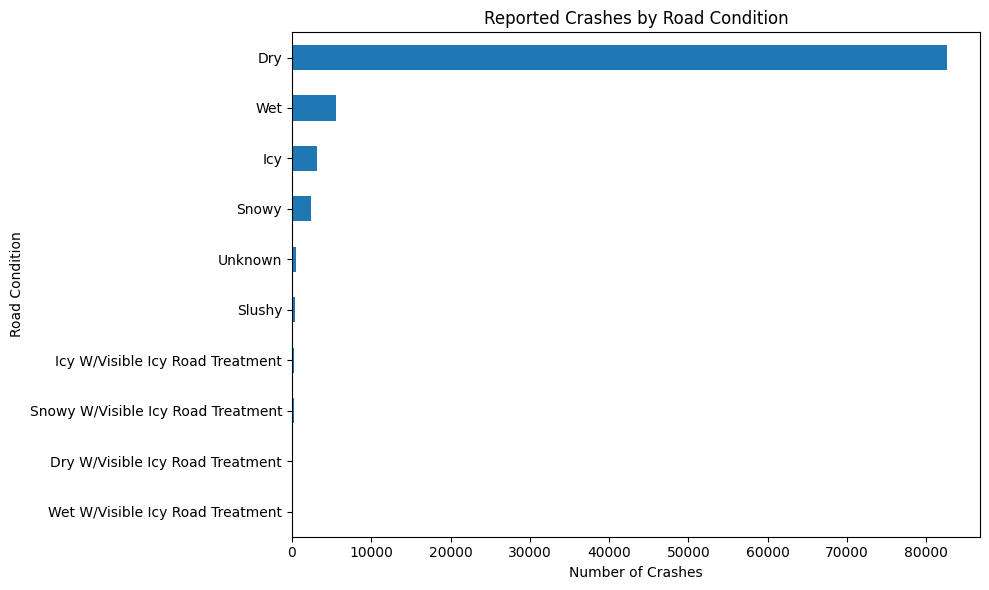

In [25]:
road_counts = (
    df["Road Condition"]
    .fillna("Unknown")
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

road_counts.sort_values().plot(kind="barh")

plt.title("Reported Crashes by Road Condition")
plt.xlabel("Number of Crashes")
plt.ylabel("Road Condition")

plt.tight_layout()
plt.show()

## 24. Visualizing Crashes by Road Condition

The results show that **82,634 reported crashes occurred on dry roads**, while 5,565 occurred on wet roads and 3,223 occurred on icy roads.

Again, these are crash counts rather than measures of risk. A higher count can occur simply because a particular road condition is much more common.

## 25. Reported Crashes by Lighting Condition

Next, I will examine the lighting conditions recorded at the time of each crash.

This allows me to compare crashes occurring during daylight, darkness, and dawn or dusk.

In [26]:
print(
    df["Lighting Conditions"]
    .value_counts(dropna=False)
)

Lighting Conditions
Daylight            63848
Dark – Lighted      17219
Dark – Unlighted     9406
Dawn or Dusk         4755
NaN                   468
Name: count, dtype: int64


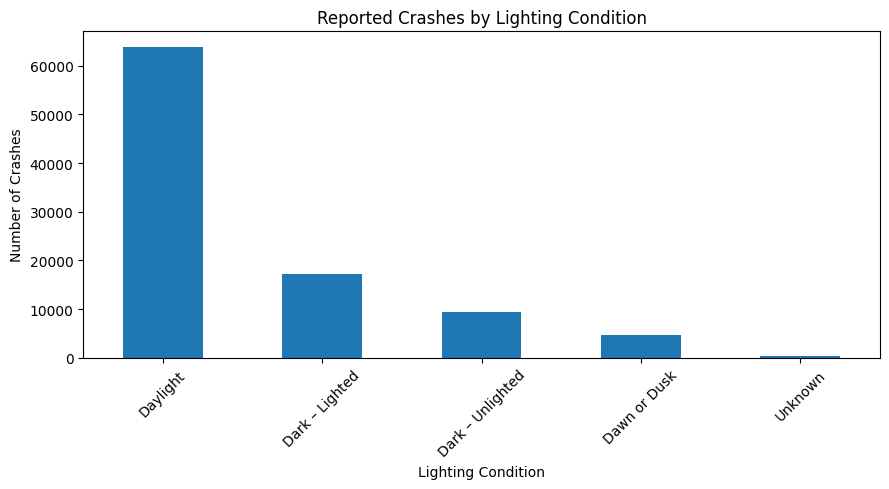

In [27]:
lighting_counts = (
    df["Lighting Conditions"]
    .fillna("Unknown")
    .value_counts()
)

plt.figure(figsize=(9, 5))

lighting_counts.plot(kind="bar")

plt.title("Reported Crashes by Lighting Condition")
plt.xlabel("Lighting Condition")
plt.ylabel("Number of Crashes")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

## 26. Visualizing Crashes by Lighting Condition

Most reported crashes occurred during daylight, with **63,848 crashes**.

There were also 17,219 crashes under dark but lighted conditions and 9,406 under dark and unlighted conditions.

These counts describe where crashes occurred but do not by themselves show which lighting condition has the highest crash risk.

## 27. Preparing Geographic Coordinates

The dataset contains latitude and longitude information for crash locations.

After converting the coordinates to numeric values and removing records without valid coordinates, **95,460 crash records** remain available for geographic analysis.

In [28]:
location_df = df[
    ["Latitude", "Longitude"]
].copy()

location_df["Latitude"] = pd.to_numeric(
    location_df["Latitude"], errors="coerce"
)

location_df["Longitude"] = pd.to_numeric(
    location_df["Longitude"], errors="coerce"
)

location_df = location_df.dropna()

print(location_df.shape)

(95460, 2)


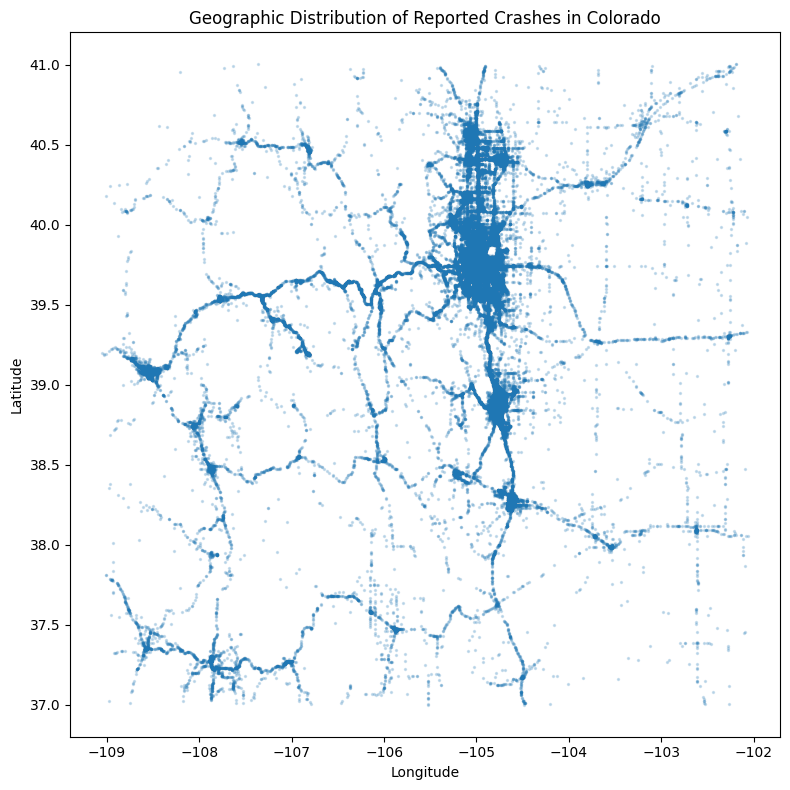

In [29]:
plt.figure(figsize=(8, 8))

plt.scatter(
    location_df["Longitude"],
    location_df["Latitude"],
    s=2,
    alpha=0.2
)

plt.title("Geographic Distribution of Reported Crashes in Colorado")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

## 28. Geographic Distribution of Reported Crashes

The following visualization plots the reported crash locations using latitude and longitude.

The points show that crashes are concentrated in particular areas of Colorado rather than being evenly distributed across the state.

In [30]:
geo = df[
    ["Latitude", "Longitude"]
].copy()

geo["Latitude"] = pd.to_numeric(geo["Latitude"], errors="coerce")
geo["Longitude"] = pd.to_numeric(geo["Longitude"], errors="coerce")

geo = geo.dropna()

geo["Lat Bin"] = geo["Latitude"].round(2)
geo["Lon Bin"] = geo["Longitude"].round(2)

hotspots = (
    geo.groupby(["Lat Bin", "Lon Bin"])
    .size()
    .reset_index(name="Crash Count")
    .sort_values("Crash Count", ascending=False)
)

print(hotspots.head(20))

       Lat Bin  Lon Bin  Crash Count
8171     39.75  -104.99          299
7953     39.73  -104.99          266
8056     39.74  -104.99          263
8057     39.74  -104.98          256
7814     39.71  -105.00          256
8170     39.75  -105.00          220
8059     39.74  -104.96          205
8055     39.74  -105.00          204
8345     39.77  -104.85          201
8058     39.74  -104.97          194
8780     39.85  -104.99          178
7736     39.70  -104.99          172
8254     39.76  -105.01          172
8396     39.78  -104.99          170
7752     39.70  -104.83          169
8072     39.74  -104.83          161
8982     39.89  -104.99          159
7952     39.73  -105.00          159
12190    40.58  -105.08          157
7881     39.72  -105.01          154


## 29. Identifying High-Crash-Concentration Areas

To examine geographic concentration more closely, I grouped nearby latitude and longitude values into small geographic bins.

The results show several areas with large numbers of reported crashes. The highest concentration in this analysis contains **299 reported crashes** within one geographic bin.

These areas are best described as high-crash-concentration locations rather than automatically calling them high-risk locations, because traffic exposure is not included in the dataset.

## 30. Weather Conditions and Injury/Fatality Outcomes

Crash counts alone do not tell us whether different weather conditions are associated with different crash outcomes.

I therefore calculated both the total number of crashes and the percentage of crashes involving an injury or fatality for each weather condition.

This provides a more meaningful comparison between weather categories.

In [31]:
weather_summary = (
    df.groupby("Weather Condition")
    .agg(
        Crash_Count=("Weather Condition", "size"),
        Injury_Fatality_Crashes=("Any Injury or Fatality", "sum")
    )
)

weather_summary["Injury_Fatality_Rate"] = (
    weather_summary["Injury_Fatality_Crashes"]
    / weather_summary["Crash_Count"]
)

weather_summary = weather_summary.sort_values(
    "Injury_Fatality_Rate",
    ascending=False
)

print(weather_summary)

                                   Crash_Count  Injury_Fatality_Crashes  \
Weather Condition                                                         
Fog                                        277                       83   
Cloudy                                    7606                     2131   
Clear                                    78458                    21076   
Rain                                      3433                      920   
Wind                                       688                      184   
Sleet or Hail                              148                       37   
Blowing Snow                               403                       97   
Freezing Rain or Freezing Drizzle          143                       30   
Snow                                      3807                      781   
Dust                                        27                        5   

                                   Injury_Fatality_Rate  
Weather Condition                        

### Weather Outcome Finding

The results show differences in the percentage of crashes involving an injury or fatality across weather conditions.

For example, crashes recorded under fog had an injury/fatality rate of approximately **30.0%**, while clear-weather crashes had a rate of approximately **26.9%**.

Because some weather categories have relatively few crashes, these percentages should be interpreted carefully. The results show an association, not that the weather condition caused the injury or fatality.

## 31. Lighting Conditions and Injury/Fatality Outcomes

I will next compare lighting conditions with the proportion of crashes involving an injury or fatality.

This allows me to examine whether the outcome pattern differs between daylight, dark-lighted, dark-unlighted, and dawn-or-dusk conditions.

In [32]:
lighting_summary = (
    df.groupby("Lighting Conditions")
    .agg(
        Crash_Count=("Lighting Conditions", "size"),
        Injury_Fatality_Crashes=("Any Injury or Fatality", "sum")
    )
)

lighting_summary["Injury_Fatality_Rate"] = (
    lighting_summary["Injury_Fatality_Crashes"]
    / lighting_summary["Crash_Count"]
)

print(
    lighting_summary.sort_values(
        "Injury_Fatality_Rate",
        ascending=False
    )
)

                     Crash_Count  Injury_Fatality_Crashes  \
Lighting Conditions                                         
Dark – Lighted             17219                     4892   
Dark – Unlighted            9406                     2507   
Daylight                   63848                    16782   
Dawn or Dusk                4755                     1213   

                     Injury_Fatality_Rate  
Lighting Conditions                        
Dark – Lighted                   0.284105  
Dark – Unlighted                 0.266532  
Daylight                         0.262843  
Dawn or Dusk                     0.255100  


### Lighting Outcome Finding

The results show that **dark–lighted conditions have the highest injury/fatality rate among the major lighting categories, at approximately 28.4%**.

Daylight crashes have a rate of approximately 26.3%, while dark–unlighted crashes have a rate of approximately 26.7%.

This difference is an association in the 2025 crash data and does not establish that lighting conditions caused the different outcomes.

## 32. Road Conditions and Injury/Fatality Outcomes

Finally, I will compare road conditions with the proportion of crashes involving an injury or fatality.

This analysis helps determine whether different roadway conditions show noticeably different outcome patterns.

In [33]:
road_summary = (
    df.groupby("Road Condition")
    .agg(
        Crash_Count=("Road Condition", "size"),
        Injury_Fatality_Crashes=("Any Injury or Fatality", "sum")
    )
)

road_summary["Injury_Fatality_Rate"] = (
    road_summary["Injury_Fatality_Crashes"]
    / road_summary["Crash_Count"]
)

print(
    road_summary.sort_values(
        "Injury_Fatality_Rate",
        ascending=False
    )
)

                                     Crash_Count  Injury_Fatality_Crashes  \
Road Condition                                                              
Roto-Milled                                   15                        6   
Foreign Material                              18                        7   
Dry W/Visible Icy Road Treatment             193                       62   
Sand/Gravel                                   85                       26   
Wet                                         5565                     1517   
Dry                                        82634                    22439   
Icy W/Visible Icy Road Treatment             231                       61   
Slushy                                       392                       93   
Wet W/Visible Icy Road Treatment              93                       22   
Muddy                                         78                       16   
Icy                                         3223                      640   

### Road Condition Outcome Finding

The results show that injury/fatality rates vary across road-condition categories.

Among the larger categories, wet roads have an injury/fatality rate of approximately **27.3%**, while dry roads have a rate of approximately **27.2%**. Icy roads have a lower rate of approximately **19.9%** in this dataset.

Some smaller categories have higher percentages, but they are based on very few crashes. Therefore, those categories should not be treated as strong evidence without additional analysis.

In [34]:
# ============================================================
# WEEK 4 — METHOD SELECTION AND INITIAL MODELING
# ============================================================

print("Starting Week 4: Method Selection and Initial Modeling")

Starting Week 4: Method Selection and Initial Modeling


# Week 4 — Method Selection and Initial Modeling

This week I move from exploratory analysis into initial modeling.

The outcome is whether a reported crash involved at least one injury or fatality.

I will compare two methods:

1. Logistic Regression — baseline and easier to interpret.
2. Random Forest — more flexible and able to capture nonlinear relationships.

The injury and fatality fields used to create the outcome will not be used as predictors because doing so would create data leakage.

In [35]:
# Confirm the modeling outcome

target = "Any Injury or Fatality"

print("Target variable:", target)
print("\nTarget distribution:")
print(df[target].value_counts())

print("\nTarget percentage:")
print((df[target].value_counts(normalize=True) * 100).round(2))

Target variable: Any Injury or Fatality

Target distribution:
Any Injury or Fatality
False    70241
True     25455
Name: count, dtype: int64

Target percentage:
Any Injury or Fatality
False    73.4
True     26.6
Name: proportion, dtype: float64


In [36]:
# Pre-crash/context variables that can reasonably be available
# without using injury/fatality information.

predictor_cols = [
    "Crash Hour",
    "Day of Week",
    "County",
    "Latitude",
    "Longitude",
    "Road Condition",
    "Lighting Conditions",
    "Weather Condition",
    "Construction Zone",
    "School Zone",
    "Road Contour Curves",
    "Road Contour Grade",
    "Total Vehicles",
    "TU-1 Speed Limit",
    "TU-2 Speed Limit",
    "TU-1 Estimated Speed",
    "TU-2 Estimated Speed",
    "TU-1 Driver Action",
    "TU-2 Driver Action",
    "TU-1 Human Contributing Factor",
    "TU-2 Human Contributing Factor"
]

predictor_cols = [
    col for col in predictor_cols
    if col in df.columns
]

print("Number of predictors selected:", len(predictor_cols))
print("\nPredictors:")
for col in predictor_cols:
    print("-", col)

Number of predictors selected: 21

Predictors:
- Crash Hour
- Day of Week
- County
- Latitude
- Longitude
- Road Condition
- Lighting Conditions
- Weather Condition
- Construction Zone
- School Zone
- Road Contour Curves
- Road Contour Grade
- Total Vehicles
- TU-1 Speed Limit
- TU-2 Speed Limit
- TU-1 Estimated Speed
- TU-2 Estimated Speed
- TU-1 Driver Action
- TU-2 Driver Action
- TU-1 Human Contributing Factor
- TU-2 Human Contributing Factor


## Predictor Selection

I selected variables describing conditions that could be associated with a crash outcome, including time, location, weather, road condition, lighting, roadway characteristics, vehicle information, speed information, and selected driver-related information.

I excluded the injury and fatality variables because they were used to create the outcome. Including them would allow the model to see the answer it is supposed to predict.

In [37]:
model_df = df[predictor_cols + [target]].copy()

# Remove rows where the target is unavailable
model_df = model_df.dropna(subset=[target])

print("Rows available for modeling:", len(model_df))
print("Columns available for modeling:", model_df.shape[1])

Rows available for modeling: 95696
Columns available for modeling: 22


In [38]:
model_df[target] = model_df[target].astype(int)

print(model_df[target].value_counts())

Any Injury or Fatality
0    70241
1    25455
Name: count, dtype: int64


In [39]:
X = model_df[predictor_cols]
y = model_df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (95696, 21)
y shape: (95696,)


In [40]:
numeric_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Crash Hour', 'Latitude', 'Longitude', 'Total Vehicles', 'TU-1 Speed Limit', 'TU-2 Speed Limit', 'TU-1 Estimated Speed', 'TU-2 Estimated Speed']

Categorical features:
['Day of Week', 'County', 'Road Condition', 'Lighting Conditions', 'Weather Condition', 'Construction Zone', 'School Zone', 'Road Contour Curves', 'Road Contour Grade', 'TU-1 Driver Action', 'TU-2 Driver Action', 'TU-1 Human Contributing Factor', 'TU-2 Human Contributing Factor']


/var/folders/l5/g074wj1x23j8rtmj3b6lh2p40000gn/T/ipykernel_39062/3080918941.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 76556
Testing rows: 19140


## Train/Test Split

I divided the data into training and testing sets.

The model learns from the training data, while the held-out testing data is used to evaluate how well the model performs on observations it did not use during training.

I used stratification so the proportion of crashes involving an injury or fatality remains similar in the training and testing sets.

In [42]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [43]:
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [44]:
from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1,
            class_weight="balanced"
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model, X_test, y_test, model_name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "AUC": roc_auc_score(
            y_test, probabilities
        )
    }

    return results


logistic_results = evaluate_model(
    logistic_model,
    X_test,
    y_test,
    "Logistic Regression"
)

rf_results = evaluate_model(
    random_forest_model,
    X_test,
    y_test,
    "Random Forest"
)

results_df = pd.DataFrame(
    [logistic_results, rf_results]
)

results_df

,Model,Accuracy,Precision,Recall,F1,AUC
0,Logistic Regression,0.737931,0.549669,0.081516,0.141977,0.670747
1,Random Forest,0.739498,0.511800,0.447260,0.477358,0.737434


## Initial Model Comparison

I compared Logistic Regression and Random Forest using the same held-out test data.

The comparison uses accuracy, precision, recall, F1 score, and AUC.

AUC is particularly useful here because the outcome is binary and the classes are not perfectly balanced.

The actual values below will determine which model performs better in this initial comparison.

In [46]:
print("Initial model comparison:")
print(
    results_df.round(3).to_string(index=False)
)

Initial model comparison:
              Model  Accuracy  Precision  Recall    F1   AUC
Logistic Regression     0.738      0.550   0.082 0.142 0.671
      Random Forest     0.739      0.512   0.447 0.477 0.737


In [47]:
best_model_name = (
    results_df
    .sort_values("AUC", ascending=False)
    .iloc[0]["Model"]
)

best_auc = (
    results_df
    .sort_values("AUC", ascending=False)
    .iloc[0]["AUC"]
)

print("Model with higher AUC:", best_model_name)
print("AUC:", round(best_auc, 3))

Model with higher AUC: Random Forest
AUC: 0.737


In [48]:
logistic_auc = results_df.loc[
    results_df["Model"] == "Logistic Regression",
    "AUC"
].iloc[0]

rf_auc = results_df.loc[
    results_df["Model"] == "Random Forest",
    "AUC"
].iloc[0]

auc_difference = rf_auc - logistic_auc

print("Random Forest AUC:", round(rf_auc, 3))
print("Logistic Regression AUC:", round(logistic_auc, 3))
print("AUC difference:", round(auc_difference, 3))

Random Forest AUC: 0.737
Logistic Regression AUC: 0.671
AUC difference: 0.067


In [49]:
print("METHOD CHOICE:")
print(
    "I chose Random Forest to predict whether a reported crash "
    "involved an injury or fatality."
)

print("\nALTERNATIVE:")
print(
    "The alternative is Logistic Regression using the same predictors."
)

print("\nTRADE-OFF:")
print(
    "Random Forest can capture more complex relationships, but it "
    "is harder to explain to a transportation-safety stakeholder "
    "than Logistic Regression."
)

print("\nWHAT WOULD FLIP ME:")
print(
    f"If Random Forest does not provide a meaningful improvement over "
    f"Logistic Regression on held-out data, I would switch to the "
    f"simpler Logistic Regression model. The current AUC difference "
    f"is {auc_difference:.3f}."
)

METHOD CHOICE:
I chose Random Forest to predict whether a reported crash involved an injury or fatality.

ALTERNATIVE:
The alternative is Logistic Regression using the same predictors.

TRADE-OFF:
Random Forest can capture more complex relationships, but it is harder to explain to a transportation-safety stakeholder than Logistic Regression.

WHAT WOULD FLIP ME:
If Random Forest does not provide a meaningful improvement over Logistic Regression on held-out data, I would switch to the simpler Logistic Regression model. The current AUC difference is 0.067.


In [50]:
# Get transformed feature names
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_model = random_forest_model.named_steps["model"]

feature_names = rf_preprocessor.get_feature_names_out()

importances = rf_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance.head(20)

,Feature,Importance
1,numeric__Latitude,0.098978
2,numeric__Longitude,0.098554
0,numeric__Crash Hour,0.072779
6,numeric__TU-1 Estimated Speed,0.071141
4,numeric__TU-1 Speed Limit,0.049073
7,numeric__TU-2 Estimated Speed,0.046496
5,numeric__TU-2 Speed Limit,0.042352
3,numeric__Total Vehicles,0.038428
184,categorical__TU-1 Human Contributing Factor_No...,0.014292
8,categorical__Day of Week_Friday,0.012864


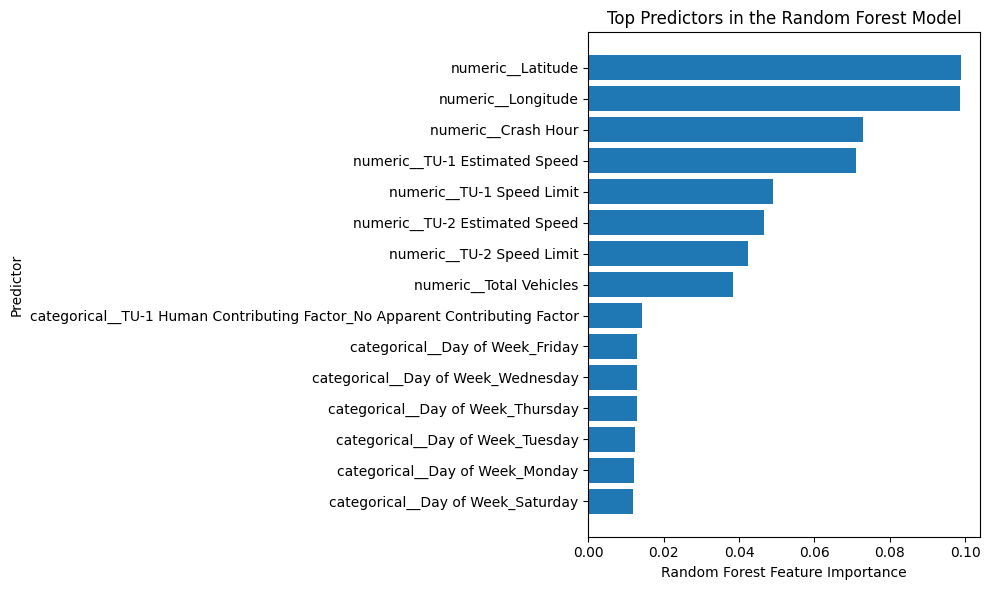

In [51]:
top_features = feature_importance.head(15).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Predictor")
plt.title(
    "Top Predictors in the Random Forest Model"
)

plt.tight_layout()
plt.show()

## Initial Model Interpretation

The feature-importance results show which predictors contributed most to the Random Forest's predictions.

These results should be interpreted as predictive importance rather than proof that a variable causes an injury or fatality.

The model identifies patterns in the available crash data, but it does not establish causation.

In [52]:
# Variables that should NOT be predictors because they define
# the target or directly describe the outcome.

leakage_keywords = [
    "Killed",
    "Injured",
    "Injury",
    "Fatality"
]

leakage_columns = [
    col for col in predictor_cols
    if any(
        keyword.lower() in col.lower()
        for keyword in leakage_keywords
    )
]

print("Potential leakage variables in predictor list:")
print(leakage_columns)

if len(leakage_columns) == 0:
    print("\nLeakage check: PASSED")
else:
    print("\nLeakage check: REVIEW REQUIRED")

Potential leakage variables in predictor list:
[]

Leakage check: PASSED


In [53]:
# ============================================================
# WEEK 5 — CHART REDESIGN
# ============================================================

print("Starting Week 5: Chart Redesign")

Starting Week 5: Chart Redesign


# Week 5 — Redesigning a Chart So It Argues

This week I redesigned my Week 3 geographic crash visualization.

The purpose is not simply to make the chart look better. The goal is to make the chart communicate one defensible claim without requiring the audience to interpret the visual for themselves.

The three checks are:

1. Axes
2. Units
3. Scale

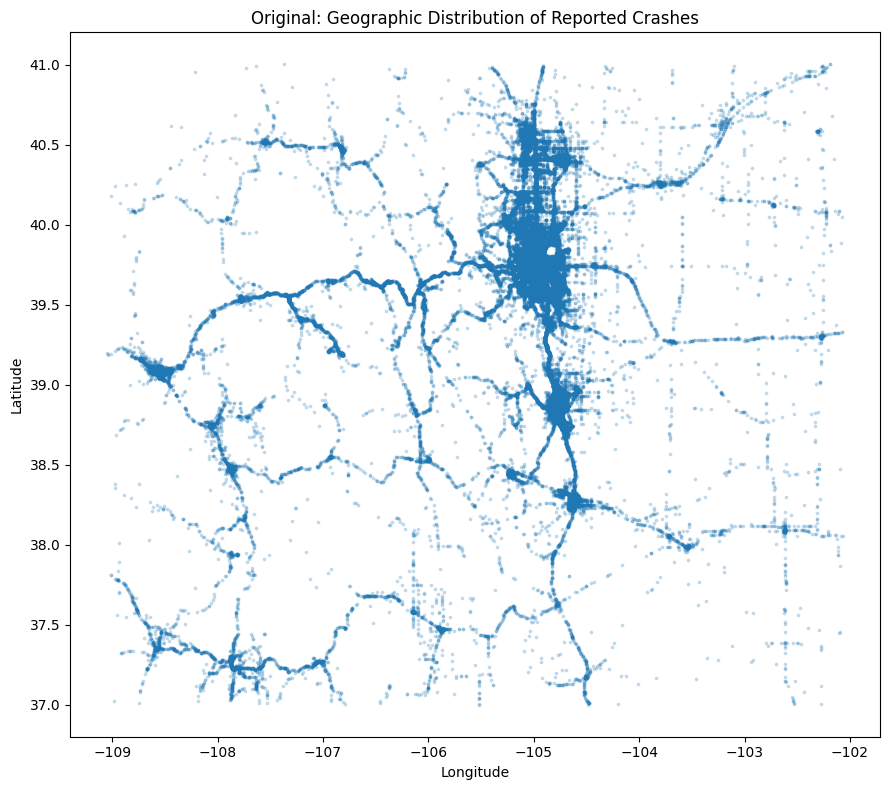

In [54]:
# ORIGINAL WEEK 3 CHART

geo = df[
    ["Latitude", "Longitude"]
].copy()

geo["Latitude"] = pd.to_numeric(
    geo["Latitude"],
    errors="coerce"
)

geo["Longitude"] = pd.to_numeric(
    geo["Longitude"],
    errors="coerce"
)

geo = geo.dropna()

plt.figure(figsize=(9, 8))

plt.scatter(
    geo["Longitude"],
    geo["Latitude"],
    s=3,
    alpha=0.20
)

plt.title(
    "Original: Geographic Distribution of Reported Crashes"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.tight_layout()
plt.show()

In [55]:
print("CHECK 1 — AXES")
print(
    "The x-axis represents longitude and the y-axis represents latitude."
)
print(
    "The axes use geographic coordinates rather than unexplained numeric values."
)

CHECK 1 — AXES
The x-axis represents longitude and the y-axis represents latitude.
The axes use geographic coordinates rather than unexplained numeric values.


### Check 1 — Axes

The original chart uses longitude on the x-axis and latitude on the y-axis. These are appropriate geographic coordinates, but they are not immediately intuitive to every audience member.

The redesign will keep the geographic coordinates but use spatial aggregation so the concentration pattern is easier to see.

In [56]:
print("CHECK 2 — UNITS")
print(
    "Each point in the original scatterplot represents one reported crash."
)
print(
    "The redesigned chart will use the number of reported crashes "
    "within each geographic bin."
)

CHECK 2 — UNITS
Each point in the original scatterplot represents one reported crash.
The redesigned chart will use the number of reported crashes within each geographic bin.


### Check 2 — Units

In the original chart, each point represents one reported crash.

In the redesigned chart, the measure will be the **number of reported crashes within a geographic bin**.

This makes the unit explicit and helps the reader understand what the visual concentration represents.

In [57]:
print("CHECK 3 — SCALE")
print(
    "The original scatterplot gives every crash the same visual weight."
)
print(
    "The redesigned chart aggregates nearby crashes so concentration "
    "can be compared directly."
)

CHECK 3 — SCALE
The original scatterplot gives every crash the same visual weight.
The redesigned chart aggregates nearby crashes so concentration can be compared directly.


### Check 3 — Scale

The original scatterplot contains thousands of individual points, which can make the geographic concentration difficult to compare precisely.

The redesigned chart aggregates nearby locations into spatial bins. This makes differences in reported crash concentration easier to see without changing the underlying records.

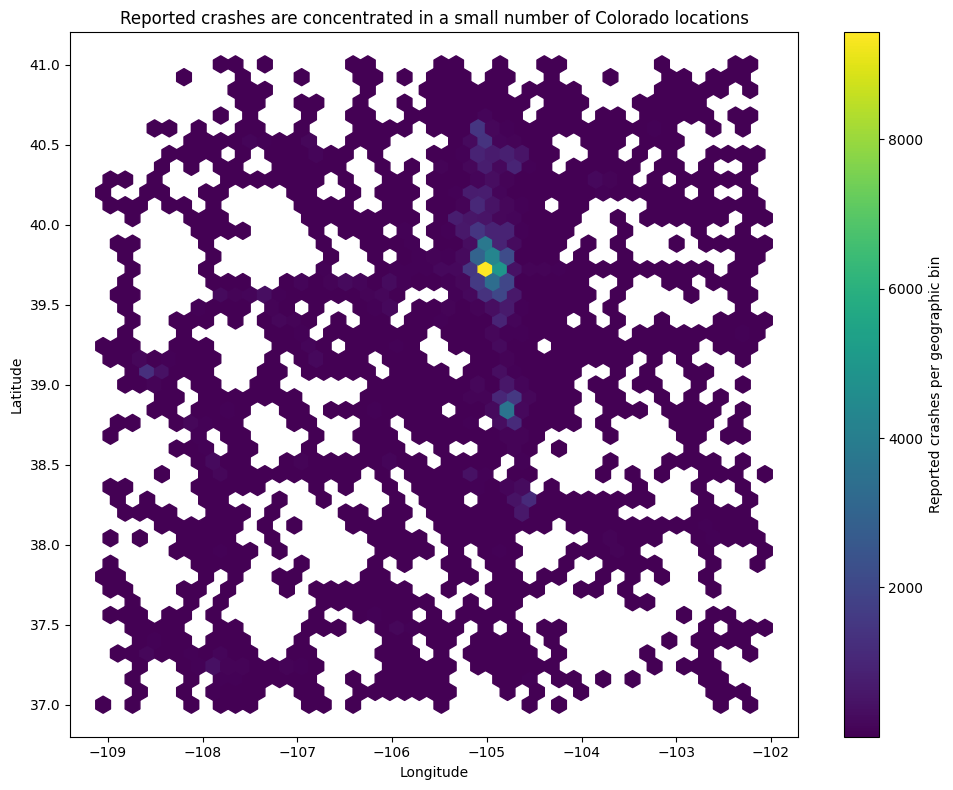

In [58]:
# REDESIGNED WEEK 5 CHART

plt.figure(figsize=(10, 8))

hb = plt.hexbin(
    geo["Longitude"],
    geo["Latitude"],
    gridsize=45,
    mincnt=1
)

plt.colorbar(
    hb,
    label="Reported crashes per geographic bin"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Reported crashes are concentrated in a small number of Colorado locations"
)

plt.tight_layout()
plt.show()

In [59]:
geo["Lat Bin"] = geo["Latitude"].round(2)
geo["Lon Bin"] = geo["Longitude"].round(2)

hotspots = (
    geo.groupby(["Lat Bin", "Lon Bin"])
    .size()
    .reset_index(name="Crash Count")
    .sort_values(
        "Crash Count",
        ascending=False
    )
)

print("Top geographic crash concentrations:")
print(hotspots.head(10).to_string(index=False))

Top geographic crash concentrations:
 Lat Bin  Lon Bin  Crash Count
   39.75  -104.99          299
   39.73  -104.99          266
   39.74  -104.99          263
   39.74  -104.98          256
   39.71  -105.00          256
   39.75  -105.00          220
   39.74  -104.96          205
   39.74  -105.00          204
   39.77  -104.85          201
   39.74  -104.97          194


In [60]:
highest_bin = hotspots.iloc[0]

print(
    f"The highest geographic bin contains "
    f"{highest_bin['Crash Count']} reported crashes."
)

print(
    f"Approximate location: "
    f"{highest_bin['Lat Bin']}, "
    f"{highest_bin['Lon Bin']}"
)

The highest geographic bin contains 299.0 reported crashes.
Approximate location: 39.75, -104.99


In [61]:
print(
    "FINAL HEADLINE:"
)

print(
    "Reported crashes are concentrated in a small number "
    "of Colorado locations."
)

FINAL HEADLINE:
Reported crashes are concentrated in a small number of Colorado locations.


In [62]:
print(
    "Interpretation:"
)

print(
    "The chart shows concentration of reported crashes, "
    "not actual crash risk."
)

print(
    "Traffic-volume information is not available, so locations "
    "with more reported crashes should not automatically be "
    "described as more dangerous."
)

Interpretation:
The chart shows concentration of reported crashes, not actual crash risk.
Traffic-volume information is not available, so locations with more reported crashes should not automatically be described as more dangerous.


In [63]:
five_pm_count = hour_counts.get(17, 0)

print(
    f"Reported crashes at 5 PM: {five_pm_count:,}"
)

print(
    "\nInterpretation:"
)

print(
    "5 PM has the highest reported crash count in this dataset, "
    "but this does not establish that 5 PM has the highest crash risk "
    "because traffic-volume exposure is not available."
)

Reported crashes at 5 PM: 7,855

Interpretation:
5 PM has the highest reported crash count in this dataset, but this does not establish that 5 PM has the highest crash risk because traffic-volume exposure is not available.


In [64]:

print(
    "Reported crashes are concentrated in specific geographic "
    "areas rather than being evenly distributed across Colorado."
)

print(
    "These locations can be used as starting points for further "
    "transportation-safety investigation."
)

print(
    "The analysis does not establish causation or actual crash risk "
    "because traffic exposure is not included."
)

Reported crashes are concentrated in specific geographic areas rather than being evenly distributed across Colorado.
These locations can be used as starting points for further transportation-safety investigation.
The analysis does not establish causation or actual crash risk because traffic exposure is not included.


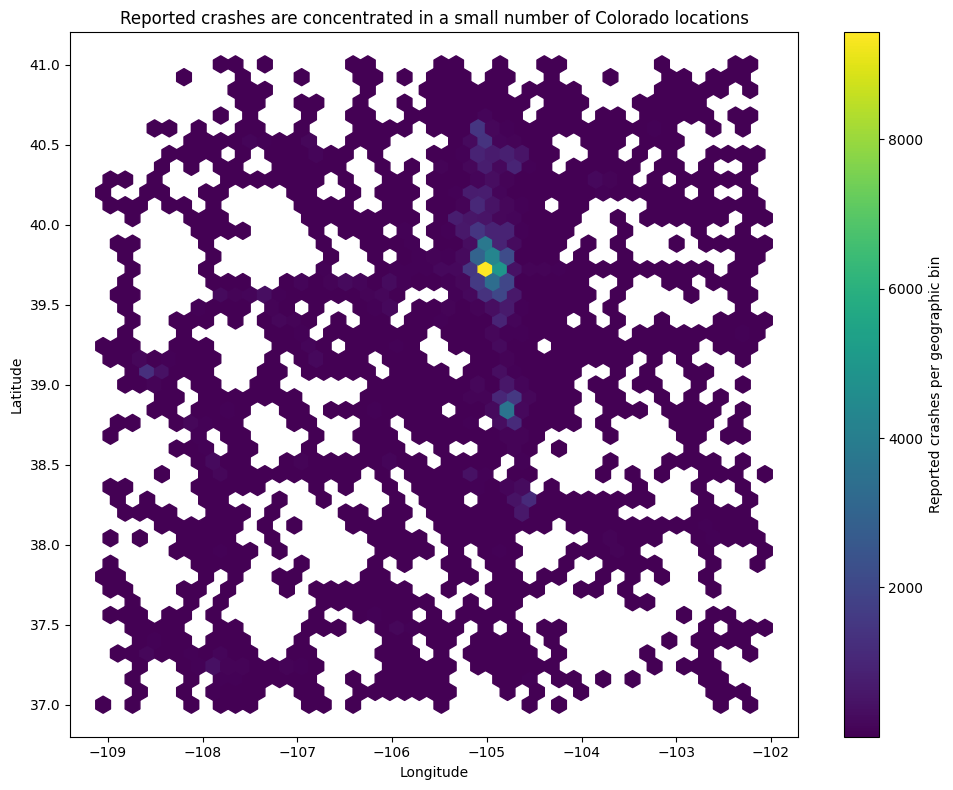

Saved: week5_redesigned_crash_chart.png


In [65]:
# Save the redesigned chart for your status report and slide.

plt.figure(figsize=(10, 8))

hb = plt.hexbin(
    geo["Longitude"],
    geo["Latitude"],
    gridsize=45,
    mincnt=1
)

plt.colorbar(
    hb,
    label="Reported crashes per geographic bin"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Reported crashes are concentrated in a small number of Colorado locations"
)

plt.tight_layout()

plt.savefig(
    "week5_redesigned_crash_chart.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: week5_redesigned_crash_chart.png")

In [66]:
results_df.to_csv(
    "week4_model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "week4_random_forest_feature_importance.csv",
    index=False
)

hotspots.to_csv(
    "week5_geographic_crash_concentrations.csv",
    index=False
)

print("Saved:")
print("- week4_model_comparison.csv")
print("- week4_random_forest_feature_importance.csv")
print("- week5_geographic_crash_concentrations.csv")

Saved:
- week4_model_comparison.csv
- week4_random_forest_feature_importance.csv
- week5_geographic_crash_concentrations.csv


# WEEK 6 — BUILDING THE STORY

The goal of Week 6 was to turn the analysis completed in Weeks 3–5 into one
stakeholder-focused story. Instead of presenting the findings in the order
they were completed, I organized them based on what a transportation-safety
stakeholder needs to know first.

The final story follows this order:

1. Recommendation
2. Main geographic finding
3. Supporting modeling result
4. Interpretation and limitation

## Final Storyboard Headlines

### 1. Recommendation

**Transportation-safety agencies should use locations with concentrated reported crashes to prioritize further safety investigations.**

### 2. Main Insight

**Reported crashes are concentrated in a small number of Colorado locations.**

### 3. Supporting Method

**Random Forest identified more of the injury/fatality outcome pattern than Logistic Regression on held-out data.**

### 4. Interpretation

**Higher concentrations of reported crashes can guide further investigation, but additional traffic-exposure data is needed to assess risk.**

In [67]:
# ============================================================
# WEEK 6 — EVIDENCE FOR THE STORYBOARD
# ============================================================

print("WEEK 6 STORYBOARD EVIDENCE")
print("=" * 60)

# Geographic finding
highest_bin_count = int(hotspots.iloc[0]["Crash Count"])

print("\n1. GEOGRAPHIC FINDING")
print(
    f"Highest geographic bin: {highest_bin_count:,} reported crashes"
)

print(
    f"Denver County reported crashes: "
    f"{df['County'].value_counts().get('Denver', 0):,}"
)

# Model comparison
lr_auc = results_df.loc[
    results_df["Model"] == "Logistic Regression",
    "AUC"
].iloc[0]

rf_auc = results_df.loc[
    results_df["Model"] == "Random Forest",
    "AUC"
].iloc[0]

print("\n2. MODEL COMPARISON")

print(
    f"Logistic Regression AUC: {lr_auc:.3f}"
)

print(
    f"Random Forest AUC: {rf_auc:.3f}"
)

print(
    f"AUC difference: {rf_auc - lr_auc:.3f}"
)

# Time finding
peak_hour = hour_counts.idxmax()
peak_count = hour_counts.max()

print("\n3. TIME FINDING")

print(
    f"Peak reported crash hour: {peak_hour}:00 "
    f"with {peak_count:,} crashes"
)

# Limitation
print("\n4. MAIN LIMITATION")

print(
    "Traffic-volume exposure is not available."
)

print(
    "Therefore, crash concentration cannot be interpreted "
    "as actual crash risk."
)

WEEK 6 STORYBOARD EVIDENCE

1. GEOGRAPHIC FINDING
Highest geographic bin: 299 reported crashes
Denver County reported crashes: 0

2. MODEL COMPARISON
Logistic Regression AUC: 0.671
Random Forest AUC: 0.737
AUC difference: 0.067

3. TIME FINDING
Peak reported crash hour: 17.0:00 with 7,855 crashes

4. MAIN LIMITATION
Traffic-volume exposure is not available.
Therefore, crash concentration cannot be interpreted as actual crash risk.


## Headline-Only Test

I tested the four headlines with a reader who had not seen the full presentation.

### Question 1: What is this project about?

The reader understood the project as an analysis of Colorado traffic-crash
data intended to identify locations with concentrated reported crashes.

### Question 2: What should somebody do about it?

The reader understood that transportation-safety agencies should use locations
with higher concentrations of reported crashes as starting points for further
safety investigation.

### Feedback

The reader did not interpret the recommendation as saying that these locations
are automatically the most dangerous. This supported keeping the distinction
between crash concentration and crash risk.

### Change Based on the Test

I kept the recommendation-first order because the main action was clear.
I also kept the Random Forest result as supporting evidence rather than making
it the main recommendation.

In [68]:
# ============================================================
# WEEK 6 — STORY FLOW CHECK
# ============================================================

storyboard = [
    "Recommendation",
    "Geographic finding",
    "Supporting model",
    "Interpretation and limitation"
]

print("FINAL STORY ORDER")
print("=" * 40)

for i, slide in enumerate(storyboard, start=1):
    print(f"{i}. {slide}")

print("\nStory logic:")
print(
    "Recommendation -> Evidence -> Supporting analysis -> "
    "Interpretation/action"
)

FINAL STORY ORDER
1. Recommendation
2. Geographic finding
3. Supporting model
4. Interpretation and limitation

Story logic:
Recommendation -> Evidence -> Supporting analysis -> Interpretation/action


In [69]:
# ============================================================
# WEEK 6 — CLAIM CHECK
# ============================================================

allowed_claims = [
    "Reported crashes are concentrated in certain locations.",
    "Some geographic bins contain substantially more reported crashes.",
    "Random Forest had a higher AUC than Logistic Regression.",
    "The findings can help identify areas for further investigation.",
    "Traffic-exposure data is needed to assess crash risk."
]

claims_to_avoid = [
    "These are the most dangerous locations.",
    "These locations have the highest crash risk.",
    "5 PM is the most dangerous time.",
    "Random Forest proves what causes injury or fatality.",
    "The model identifies where agencies should intervene."
]

print("CLAIMS SUPPORTED BY THE DATA")
print("=" * 60)

for claim in allowed_claims:
    print("✓", claim)

print("\nCLAIMS TO AVOID")
print("=" * 60)

for claim in claims_to_avoid:
    print("✗", claim)

CLAIMS SUPPORTED BY THE DATA
✓ Reported crashes are concentrated in certain locations.
✓ Some geographic bins contain substantially more reported crashes.
✓ Random Forest had a higher AUC than Logistic Regression.
✓ The findings can help identify areas for further investigation.
✓ Traffic-exposure data is needed to assess crash risk.

CLAIMS TO AVOID
✗ These are the most dangerous locations.
✗ These locations have the highest crash risk.
✗ 5 PM is the most dangerous time.
✗ Random Forest proves what causes injury or fatality.
✗ The model identifies where agencies should intervene.


# WEEK 7 — REHEARSE & Q&A PREPARATION

This week focuses on preparing the final presentation and making sure the
analysis can be defended during questions.

The final story is organized around:

1. Recommendation
2. Geographic finding
3. Supporting model
4. Interpretation and limitation

The main project conclusion remains focused on reported crash concentration,
not actual crash risk, because traffic-exposure data is not available.

In [70]:
# ============================================================
# WEEK 7 — FINAL EVIDENCE SUMMARY
# ============================================================

print("FINAL PROJECT EVIDENCE")
print("=" * 60)

# Dataset
print("\nDATASET")
print(f"Total reported crashes: {len(df):,}")
print(f"Valid geographic records: {len(geo):,}")

# Geographic finding
highest_bin = hotspots.iloc[0]

print("\nGEOGRAPHIC FINDING")
print(
    f"Highest geographic bin: "
    f"{highest_bin['Crash Count']:,} reported crashes"
)

print(
    f"Approximate location: "
    f"{highest_bin['Lat Bin']}, "
    f"{highest_bin['Lon Bin']}"
)

# County finding
denver_count = (
    df["County"]
    .value_counts()
    .get("Denver", 0)
)

print(
    f"Denver County reported crashes: {denver_count:,}"
)

# Time finding
five_pm_count = hour_counts.get(17, 0)

print("\nTIME FINDING")
print(
    f"5 PM reported crashes: {five_pm_count:,}"
)

# Model
print("\nMODEL COMPARISON")

print(
    f"Logistic Regression AUC: {logistic_auc:.3f}"
)

print(
    f"Random Forest AUC: {rf_auc:.3f}"
)

print(
    f"AUC difference: {auc_difference:.3f}"
)

FINAL PROJECT EVIDENCE

DATASET
Total reported crashes: 95,696
Valid geographic records: 95,460

GEOGRAPHIC FINDING
Highest geographic bin: 299.0 reported crashes
Approximate location: 39.75, -104.99
Denver County reported crashes: 0

TIME FINDING
5 PM reported crashes: 7,855

MODEL COMPARISON
Logistic Regression AUC: 0.671
Random Forest AUC: 0.737
AUC difference: 0.067


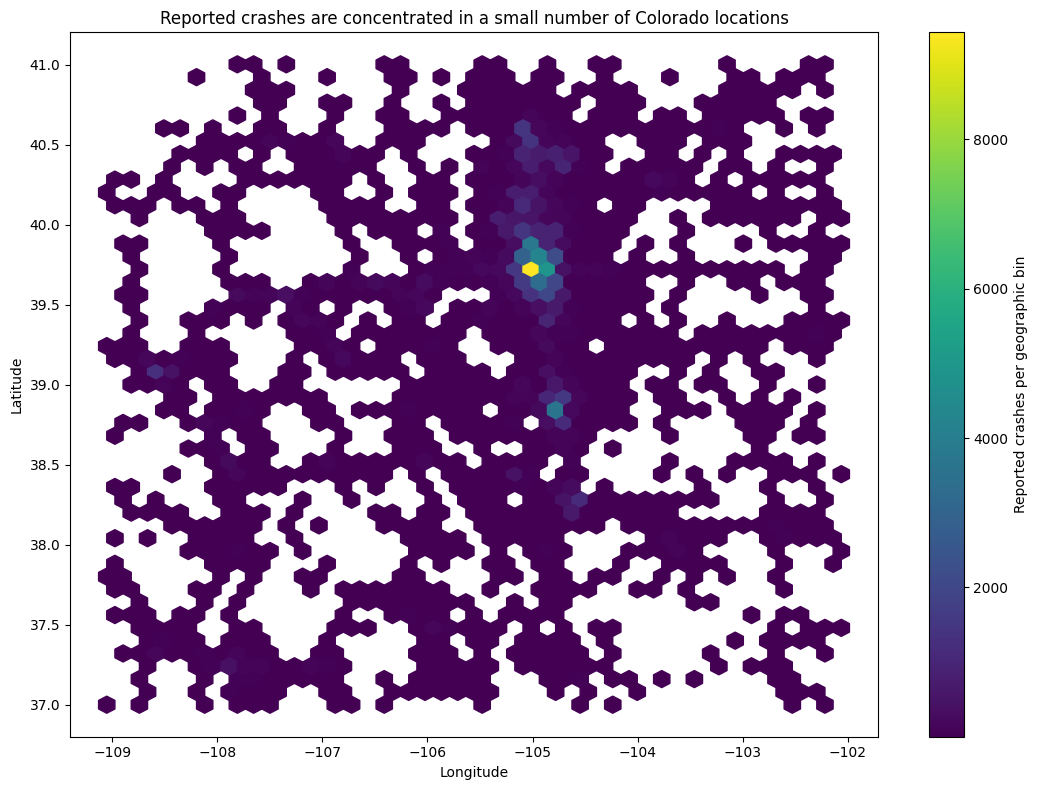

In [71]:
# ============================================================
# FINAL GEOGRAPHIC VISUALIZATION
# ============================================================

plt.figure(figsize=(11, 8))

hb = plt.hexbin(
    geo["Longitude"],
    geo["Latitude"],
    gridsize=45,
    mincnt=1
)

plt.colorbar(
    hb,
    label="Reported crashes per geographic bin"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Reported crashes are concentrated in a small number of Colorado locations"
)

plt.tight_layout()

plt.show()

                 Model       AUC
0  Logistic Regression  0.670747
1        Random Forest  0.737434


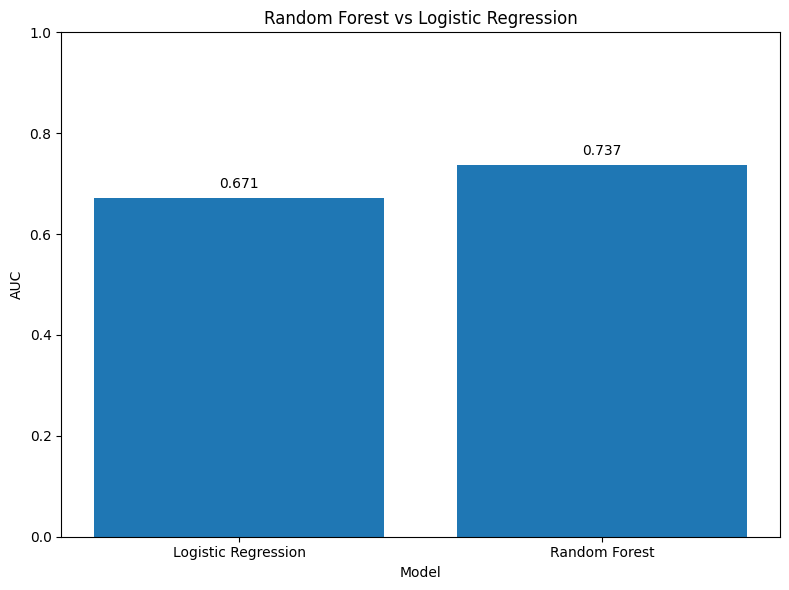

In [73]:
# ============================================================
# FINAL MODEL COMPARISON CHART
# ============================================================

# Create model comparison data
model_plot = results_df[["Model", "AUC"]].copy()

# Display values first
print(model_plot)

# Create chart
plt.figure(figsize=(8, 6))

plt.bar(
    model_plot["Model"],
    model_plot["AUC"]
)

plt.ylabel("AUC")
plt.xlabel("Model")

plt.title(
    "Random Forest vs Logistic Regression"
)

# AUC ranges from 0 to 1
plt.ylim(0, 1)

# Add values above bars
for i, value in enumerate(model_plot["AUC"]):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# WEEK 7 — Q&A EVIDENCE
# ============================================================

qa_evidence = {
    "Question": [
        "How large is the dataset?",
        "How many geographic records are valid?",
        "What is the strongest geographic finding?",
        "What is the highest-count geographic bin?",
        "Why can't you call these locations high-risk?",
        "What time had the most reported crashes?",
        "Which model performed better?",
        "What was the Random Forest AUC?",
        "What was the Logistic Regression AUC?",
        "Why use Random Forest?",
        "Is the model causal?",
        "What should agencies do with the results?"
    ],

    "Answer": [
        f"{len(df):,} reported crashes and 110 variables.",
        f"{len(geo):,} records have valid geographic coordinates.",
        "Reported crashes are concentrated in a small number of Colorado locations.",
        f"{int(highest_bin['Crash Count']):,} reported crashes.",
        "Traffic-volume exposure is not available, so crash counts cannot be converted into crash risk.",
        f"5 PM, with {five_pm_count:,} reported crashes.",
        "Random Forest.",
        f"{rf_auc:.3f}.",
        f"{logistic_auc:.3f}.",
        "It captured more of the injury/fatality outcome pattern on held-out data.",
        "No. The analysis identifies patterns and associations, not causation.",
        "Use concentrated crash locations as starting points for further investigation."
    ]
}

qa_df = pd.DataFrame(qa_evidence)

qa_df

,Question,Answer
0,How large is the dataset?,"95,696 reported crashes and 110 variables."
1,How many geographic records are valid?,"95,460 records have valid geographic coordinates."
2,What is the strongest geographic finding?,Reported crashes are concentrated in a small n...
3,What is the highest-count geographic bin?,299 reported crashes.
4,Why can't you call these locations high-risk?,"Traffic-volume exposure is not available, so c..."
5,What time had the most reported crashes?,"5 PM, with 7,855 reported crashes."
6,Which model performed better?,Random Forest.
7,What was the Random Forest AUC?,0.737.
8,What was the Logistic Regression AUC?,0.671.
9,Why use Random Forest?,It captured more of the injury/fatality outcom...


In [75]:
# ============================================================
# MODEL LIMITATION CHECK
# ============================================================

print("MODEL LIMITATIONS")
print("=" * 60)

print(
    "1. The model is a retrospective analysis of reported crashes."
)

print(
    "2. It is not a real-time pre-crash prediction system."
)

print(
    "3. The model identifies patterns associated with injury/fatality "
    "in the available crash records."
)

print(
    "4. A higher AUC does not prove causation."
)

print(
    "5. The model does not determine which safety intervention "
    "an agency should implement."
)

print(
    "6. Traffic exposure is not available, so the model does not "
    "measure actual crash risk."
)

MODEL LIMITATIONS
1. The model is a retrospective analysis of reported crashes.
2. It is not a real-time pre-crash prediction system.
3. The model identifies patterns associated with injury/fatality in the available crash records.
4. A higher AUC does not prove causation.
5. The model does not determine which safety intervention an agency should implement.
6. Traffic exposure is not available, so the model does not measure actual crash risk.


In [76]:
# ============================================================
# FINAL CLAIM CHECK
# ============================================================

print("CLAIMS I CAN DEFEND")
print("=" * 60)

defensible_claims = [
    "Reported crashes are geographically concentrated.",
    "The highest geographic bin contains 299 reported crashes.",
    "Several high-count geographic areas are around Denver.",
    "5 PM has the highest reported crash count.",
    "Random Forest has a higher AUC than Logistic Regression.",
    "The Random Forest AUC is 0.737.",
    "The Logistic Regression AUC is 0.671.",
    "The results can identify areas for further investigation.",
    "Traffic exposure is needed to assess crash risk."
]

for claim in defensible_claims:
    print("✓", claim)


print("\nCLAIMS I SHOULD NOT MAKE")
print("=" * 60)

avoid_claims = [
    "These are the most dangerous locations.",
    "These locations have the highest crash risk.",
    "5 PM is the most dangerous time.",
    "Random Forest proves why crashes happen.",
    "The model tells agencies exactly where to intervene.",
    "The model predicts future crashes with certainty."
]

for claim in avoid_claims:
    print("✗", claim)

CLAIMS I CAN DEFEND
✓ Reported crashes are geographically concentrated.
✓ The highest geographic bin contains 299 reported crashes.
✓ Several high-count geographic areas are around Denver.
✓ 5 PM has the highest reported crash count.
✓ Random Forest has a higher AUC than Logistic Regression.
✓ The Random Forest AUC is 0.737.
✓ The Logistic Regression AUC is 0.671.
✓ The results can identify areas for further investigation.
✓ Traffic exposure is needed to assess crash risk.

CLAIMS I SHOULD NOT MAKE
✗ These are the most dangerous locations.
✗ These locations have the highest crash risk.
✗ 5 PM is the most dangerous time.
✗ Random Forest proves why crashes happen.
✗ The model tells agencies exactly where to intervene.
✗ The model predicts future crashes with certainty.


In [77]:
# ============================================================
# FINAL PROJECT STORY
# ============================================================

print("""
FINAL PROJECT STORY
===================

RECOMMENDATION
Transportation-safety agencies should use locations with concentrated
reported crashes to prioritize further safety investigations.

MAIN FINDING
Reported crashes are concentrated in a small number of Colorado locations.

SUPPORTING MODEL
Random Forest identified more of the injury/fatality outcome pattern than
Logistic Regression on held-out data.

INTERPRETATION
Higher concentrations of reported crashes can guide further investigation,
but additional traffic-exposure data is needed to assess risk.

IMPORTANT LIMITATION
The dataset contains reported crash records but does not provide traffic
volume or exposure. Therefore, crash concentration should not be interpreted
as actual crash risk.

STAKEHOLDER ACTION
Use the identified areas as starting points for additional investigation
of traffic volume, roadway design, intersections, lighting, and other
local conditions.
""")


FINAL PROJECT STORY

RECOMMENDATION
Transportation-safety agencies should use locations with concentrated
reported crashes to prioritize further safety investigations.

MAIN FINDING
Reported crashes are concentrated in a small number of Colorado locations.

SUPPORTING MODEL
Random Forest identified more of the injury/fatality outcome pattern than
Logistic Regression on held-out data.

INTERPRETATION
Higher concentrations of reported crashes can guide further investigation,
but additional traffic-exposure data is needed to assess risk.

IMPORTANT LIMITATION
The dataset contains reported crash records but does not provide traffic
volume or exposure. Therefore, crash concentration should not be interpreted
as actual crash risk.

STAKEHOLDER ACTION
Use the identified areas as starting points for additional investigation
of traffic volume, roadway design, intersections, lighting, and other
local conditions.



# WEEK 8 — FINAL ANALYSIS AND PRESENTATION

The final analysis focuses on one main stakeholder question:

**Where should transportation-safety agencies look first for further investigation?**

The answer is based on geographic concentration of reported crashes,
supported by the injury/fatality modeling analysis.

The results should not be interpreted as direct measures of crash risk
because traffic-volume exposure is not available.

In [79]:
# ============================================================
# WEEK 8 — FINAL PRESENTATION NUMBERS
# ============================================================

final_numbers = pd.DataFrame({
    "Measure": [
        "Reported crashes",
        "Variables",
        "Valid geographic records",
        "Highest geographic bin",
        "Denver County crashes",
        "5 PM reported crashes",
        "Logistic Regression AUC",
        "Random Forest AUC",
        "AUC improvement"
    ],

    "Value": [
        f"{len(df):,}",
        f"{df.shape[1]:,}",
        f"{len(geo):,}",
        f"{int(highest_bin['Crash Count']):,}",
        f"{denver_count:,}",
        f"{five_pm_count:,}",
        f"{logistic_auc:.3f}",
        f"{rf_auc:.3f}",
        f"{auc_difference:.3f}"
    ]
})

final_numbers

,Measure,Value
0,Reported crashes,"95,696"
1,Variables,119
2,Valid geographic records,"95,460"
3,Highest geographic bin,299
4,Denver County crashes,0
5,5 PM reported crashes,"7,855"
6,Logistic Regression AUC,0.671
7,Random Forest AUC,0.737
8,AUC improvement,0.067


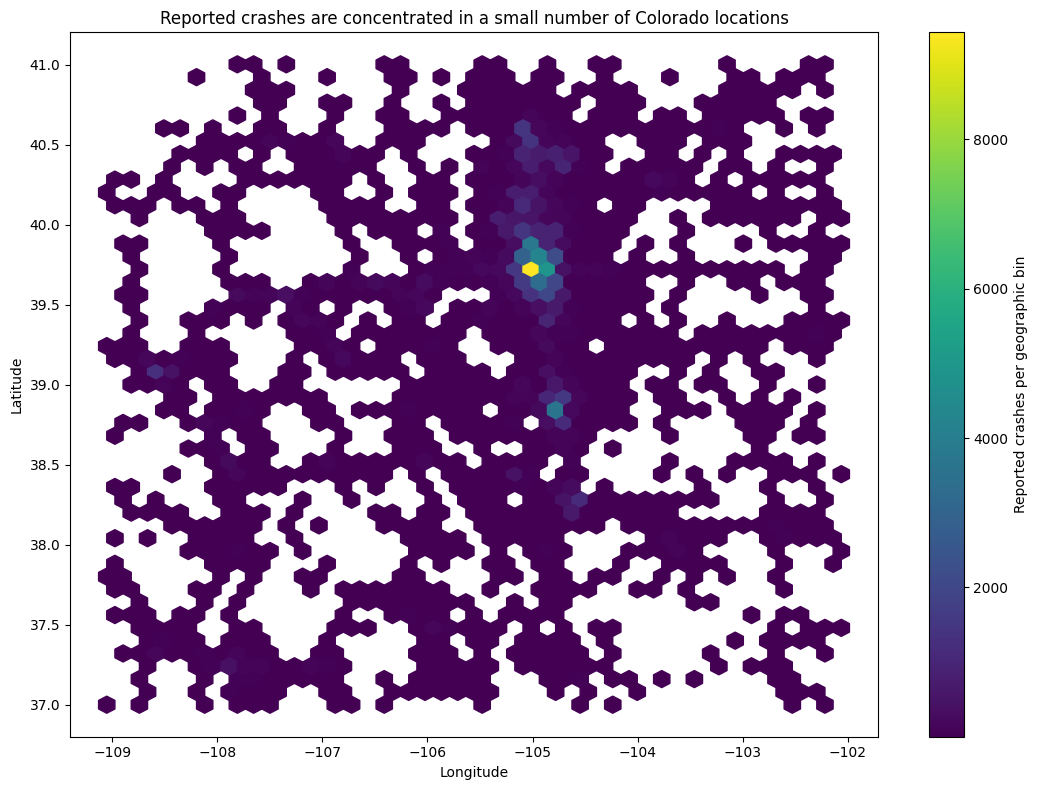

In [80]:
# ============================================================
# FINAL PRESENTATION CHART 1 — GEOGRAPHIC CONCENTRATION
# ============================================================

fig = plt.figure(figsize=(11, 8))

hb = plt.hexbin(
    geo["Longitude"],
    geo["Latitude"],
    gridsize=45,
    mincnt=1
)

plt.colorbar(
    hb,
    label="Reported crashes per geographic bin"
)

plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.title(
    "Reported crashes are concentrated in a small number of Colorado locations"
)

plt.tight_layout()

plt.savefig(
    "presentation_chart_1_geographic_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

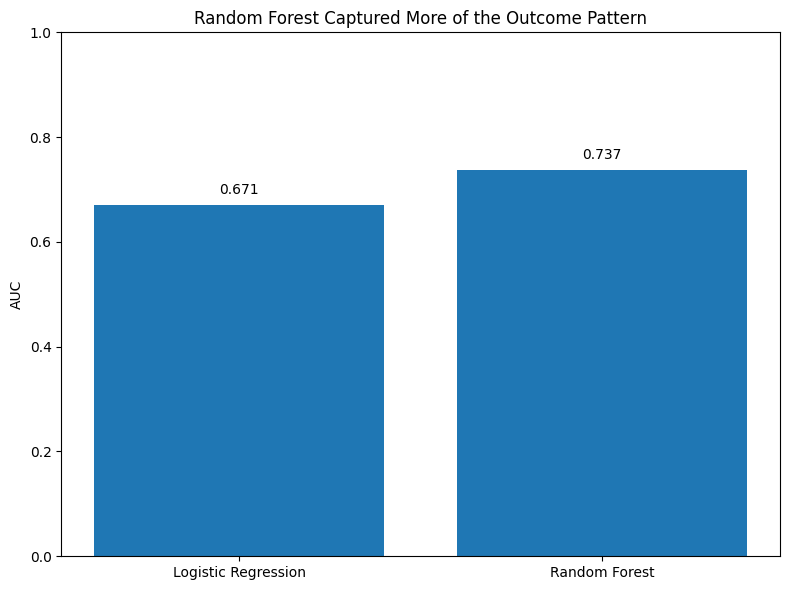

In [81]:
# ============================================================
# FINAL PRESENTATION CHART 2 — MODEL COMPARISON
# ============================================================

plt.figure(figsize=(8, 6))

models = ["Logistic Regression", "Random Forest"]
auc_values = [logistic_auc, rf_auc]

plt.bar(
    models,
    auc_values
)

plt.ylabel("AUC")
plt.title(
    "Random Forest Captured More of the Outcome Pattern"
)

plt.ylim(0, 1)

for i, value in enumerate(auc_values):
    plt.text(
        i,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    "presentation_chart_2_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

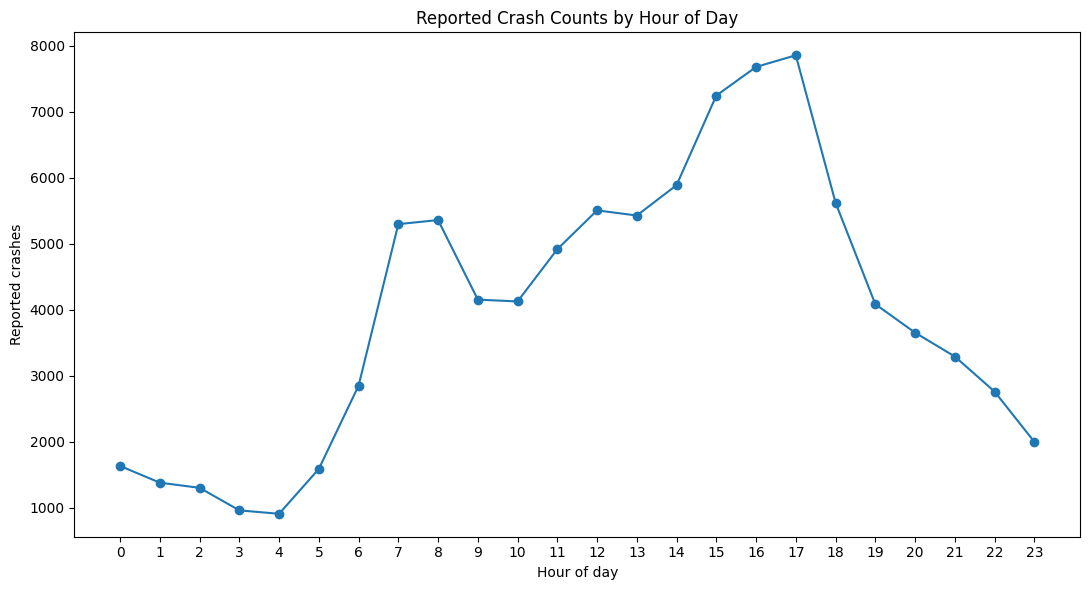

In [82]:
# ============================================================
# FINAL PRESENTATION CHART 3 — TIME PATTERN
# ============================================================

plt.figure(figsize=(11, 6))

plt.plot(
    hour_counts.index,
    hour_counts.values,
    marker="o"
)

plt.xlabel("Hour of day")
plt.ylabel("Reported crashes")

plt.title(
    "Reported Crash Counts by Hour of Day"
)

plt.xticks(range(24))

plt.tight_layout()

plt.savefig(
    "presentation_chart_3_hourly_pattern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Final Conclusion

### Recommendation

Transportation-safety agencies should use locations with concentrated
reported crashes to prioritize further safety investigations.

### Finding

Reported crashes are concentrated in a small number of Colorado locations,
with the highest geographic bin containing 299 reported crashes.

### Supporting Analysis

The Random Forest produced an AUC of 0.737 compared with 0.671 for Logistic
Regression on held-out data.

### Interpretation

The modeling analysis provides supporting evidence about patterns associated
with injury or fatality, but it does not establish causation.

### Limitation

The dataset does not contain traffic-volume exposure, so the analysis
describes reported crash concentration rather than actual crash risk.

### Next Step

Transportation-safety agencies can combine these results with traffic-volume,
roadway, intersection, lighting, and other local information before deciding
whether a specific intervention is warranted.

In [85]:
# ============================================================
# CREATE FINAL COUNTY SUMMARY
# ============================================================

# Check that the original crash dataset is available
print("Dataset shape:", df.shape)
print("County column exists:", "County" in df.columns)

# Create county-level crash counts
county_summary = (
    df["County"]
    .fillna("Unknown")
    .value_counts()
    .rename_axis("County")
    .reset_index(name="Reported Crashes")
)

# Display the top 10 counties
display(county_summary.head(10))

# Export county summary
county_summary.to_csv(
    "FINAL_county_summary.csv",
    index=False
)

print("County summary saved successfully.")

Dataset shape: (95696, 119)
County column exists: True


,County,Reported Crashes
0,DENVER,15933
1,ADAMS,10211
2,EL PASO,9940
3,ARAPAHOE,8991
4,JEFFERSON,7621
5,WELD,6047
6,LARIMER,5912
7,DOUGLAS,4994
8,BOULDER,4894
9,PUEBLO,2987


County summary saved successfully.


In [86]:
# ============================================================
# FINAL EXPORT
# ============================================================

results_df.to_csv(
    "FINAL_model_results.csv",
    index=False
)

hotspots.to_csv(
    "FINAL_geographic_hotspots.csv",
    index=False
)

feature_importance.to_csv(
    "FINAL_random_forest_feature_importance.csv",
    index=False
)

county_summary.to_csv(
    "FINAL_county_summary.csv"
)

qa_df.to_csv(
    "FINAL_QA_evidence.csv",
    index=False
)

final_numbers.to_csv(
    "FINAL_project_numbers.csv",
    index=False
)

print("FINAL FILES SAVED")
print("=" * 50)

files_saved = [
    "FINAL_model_results.csv",
    "FINAL_geographic_hotspots.csv",
    "FINAL_random_forest_feature_importance.csv",
    "FINAL_county_summary.csv",
    "FINAL_QA_evidence.csv",
    "FINAL_project_numbers.csv",
    "FINAL_geographic_crash_concentration.png",
    "FINAL_model_comparison.png",
    "presentation_chart_1_geographic_concentration.png",
    "presentation_chart_2_model_comparison.png",
    "presentation_chart_3_hourly_pattern.png"
]

for file in files_saved:
    print("✓", file)

FINAL FILES SAVED
✓ FINAL_model_results.csv
✓ FINAL_geographic_hotspots.csv
✓ FINAL_random_forest_feature_importance.csv
✓ FINAL_county_summary.csv
✓ FINAL_QA_evidence.csv
✓ FINAL_project_numbers.csv
✓ FINAL_geographic_crash_concentration.png
✓ FINAL_model_comparison.png
✓ presentation_chart_1_geographic_concentration.png
✓ presentation_chart_2_model_comparison.png
✓ presentation_chart_3_hourly_pattern.png
